# Исследование рынка заведений общественного питания Москвы

## Описание проекта

Инвесторы фонда *Shut Up and Take My Money* планируют открыть заведение общественного питания в Москве, но пока не определились с форматом, расположением и ценовой политикой. Чтобы подготовить основу для решения, я проведу исследовательский анализ рынка Москвы по данным сервисов Яндекс Карты и Яндекс Бизнес за лето 2022 года. Результаты помогут выбрать перспективный формат заведения и ориентиры по локации, вместимости и среднему чеку.

## Цель и задачи

**Цель:** провести исследовательский анализ рынка заведений общественного питания Москвы.

**Задачи:** 
1. Загрузить данные и познакомиться с их содержимым.
2. Провести предобработку данных.
3. Провести исследовательский анализ данных:
    - изучить данные более детально;
    - ответить на поставленные вопросы:  
        1) Какие категории заведений представлены в данных?  
        2) Какие административные районы Москвы присутствуют в данных?  
        3) Изучить соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения  
        4) Исследовать количество посадочных мест в заведениях  
        5) Исследовать рейтинг заведений  
        6) Изучить, с какими данными показывают самую сильную корреляцию рейтинги заведений?  
        7) Сгруппировать данные по названиям заведений и найти топ-15 популярных сетей в Москве  
        8) Изучить вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы.  
       
4. Сформулировать выводы по проведённому анализу.

## Описание данных

Данные состоят из двух датасетов:  
- `rest_info.csv` с информацией о заведениях общественного питания
- `rest_price.csv` с информацией о среднем чеке в заведениях общественного питания

### Описание датасета `rest_info.csv`

- `name` название заведения;
- `address` адрес заведения;
- `district` административный район, в котором находится заведение, например Центральный административный округ;
- `category` категория заведения, например «кафе», «пиццерия» или «кофейня»;
- `hours` информация о днях и часах работы;
- `rating` рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
- `chain` число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки): 0 — заведение не является сетевым; 1 — заведение является сетевым.
- `seats` количество посадочных мест.

### Описание датасета `rest_price.csv`  

- `price` категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- `avg_bill` строка, которая хранит среднюю стоимость заказа в виде диапазона, например:  
    «Средний счёт: 1000–1500 ₽»;  
    «Цена чашки капучино: 130–220 ₽»;  
    «Цена бокала пива: 400–600 ₽».  
    и так далее;  
- `middle_avg_bill` число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»:  
    Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.  
    Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.  
    Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.  
- `middle_coffee_cup` число с оценкой одной чашки капучино, которое указано только для значений из столбца   avg_bill, начинающихся с подстроки «Цена одной чашки капучино»:  
    Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.  
    Если в строке указано одно число, то это цена без диапазона, то в столбец войдёт это число.  
    Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.



## 1. Загрузка данных и знакомство с ними  


Сначала я загрузила библиотеки и датасеты `rest_info` и `rest_price`. Для работы я использовала pandas, библиотеки визуализации matplotlib и seaborn, а также phik для построения матрицы корреляции.

### 1.1 Загрузка данных


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import phik


In [3]:
# единый стиль визуализаций
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', None)


In [4]:
# ссылки оставлены как запасной вариант
try:
    info_df = pd.read_csv('/datasets/rest_info.csv')
    price_df = pd.read_csv('/datasets/rest_price.csv')
except FileNotFoundError:
    info_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_info.csv')
    price_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_price.csv')


### 1.2–1.4 Знакомство с данными, общая информация и первичные выводы

In [5]:
info_df.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00–02:00",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [6]:
info_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


Смотрим датасет `rest_info.csv`: он содержит 8406 строк и 9 столбцов. Типы данных в целом корректны: рейтинг и количество мест представлены числами, признак сети целым числом, остальные поля строками. Пропуски есть в `hours` и `seats`; их причины и способ обработки смотрю на этапе предобработки.


In [7]:
price_df.head(10)

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN
5,96ebceb1a09e4e3191133b9fe0379a64,средние,Средний счёт:199 ₽,199.0,NaN
6,0243288b78024af090b8e947842c969c,средние,Средний счёт:200–300 ₽,250.0,NaN
7,36aeb0ffa69c48fdb0021549520deb10,средние,Средний счёт:от 500 ₽,500.0,NaN
8,487167877eb04288bc90d4fa80646fc2,средние,Средний счёт:1000–1200 ₽,1100.0,NaN
9,ac32978af97641bfacf996e7f5a50ee5,средние,Цена бокала пива:250–350 ₽,NaN,NaN


In [8]:
price_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


Затем я изучила датасет `rest_price.csv`: он содержит 4058 строк и 5 столбцов. Типы данных соответствуют содержимому. Пропуски есть во всех ценовых полях, кроме `id`. Часть из них ожидаема: таблица содержит сведения только для части заведений, а `middle_avg_bill` и `middle_coffee_cup` заполняются для разных типов строк в `avg_bill`. Поэтому большое число пропусков само по себе не свидетельствует об ошибке.

### 1.5 Подготовка единого датафрейма  

In [9]:
# сохраняем все заведения из основной таблицы и добавляем доступную ценовую информацию
df = info_df.merge(price_df, on='id', how='left', validate='one_to_one')
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 853.9+ KB


In [10]:
initial_rows = len(df)
print(f'После объединения: {df.shape[0]} строк и {df.shape[1]} столбцов')


После объединения: 8406 строк и 13 столбцов


## 2. Предобработка данных

### 2.1 Оптимизация типов данных



In [11]:
# значения chain принимают только 0 и 1, поэтому достаточно целого типа
df['chain'] = df['chain'].astype('int8')
df.dtypes


id                    object
name                  object
category              object
address               object
district              object
hours                 object
rating               float64
chain                   int8
seats                float64
price                 object
avg_bill              object
middle_avg_bill      float64
middle_coffee_cup    float64
dtype: object

Остальные типы данных корректны. `seats`, `middle_avg_bill` и `middle_coffee_cup` остаются `float`, поскольку содержат пропуски. Текстовые признаки оставляем в формате `object`: это удобно для нормализации строк и последующего анализа.


### 2.2 Проверка пропусков

Посчитаем абсолютное и относительное количество пропусков во всех столбцах объединённого датафрейма.


In [12]:
missing_stats = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_share_pct': (df.isna().mean() * 100).round(2)
})
missing_stats[missing_stats['missing_count'] > 0]


,missing_count,missing_share_pct
hours,536,6.38
seats,3611,42.96
price,5091,60.56
avg_bill,4590,54.60
middle_avg_bill,5257,62.54
middle_coffee_cup,7871,93.64


In [13]:
# доля заведений, для которых есть запись в таблице цен
price_coverage = df['id'].isin(price_df['id']).mean()
print(f'Ценовая таблица содержит записи для {price_coverage:.1%} заведений основной таблицы')


Ценовая таблица содержит записи для 48.3% заведений основной таблицы


In [14]:
# проверим, соответствуют ли числовые поля тексту в avg_bill
bill_rows = df['avg_bill'].str.startswith('Средний счёт', na=False)
coffee_rows = df['avg_bill'].str.contains('капучино', case=False, na=False)

pd.DataFrame({
    'тип строки': ['Средний счёт', 'Цена капучино'],
    'строк в avg_bill': [bill_rows.sum(), coffee_rows.sum()],
    'заполнено числовое поле': [df['middle_avg_bill'].notna().sum(),
                                df['middle_coffee_cup'].notna().sum()]
})


,тип строки,строк в avg_bill,заполнено числовое поле
0,Средний счёт,3149,3149
1,Цена капучино,535,535


Пропуски неслучайны, вот что думаю:

- `hours` отсутствует примерно у 6,4% заведений: режим работы мог быть не указан пользователем или не найден в источнике;
- `seats` отсутствует примерно у 43% заведений: число мест могло быть не заполнено, а часть заведений может работать преимущественно навынос;
- ценовые поля заполнены только для части заведений, поскольку `rest_price.csv` содержит меньше строк, чем основная таблица;
- `middle_avg_bill` и `middle_coffee_cup` являются спец. полями: первое заполняется для строк о среднем счёте, второе для строк о капучино.

Заполнять эти пропуски средними или нулевыми думаю не надо, это исказит распределения. Я оставила их как `NaN` и исключала только из тех расчётов, где нужен конкретный показатель.


Проверим, как доля пропусков в `seats` различается между категориями.


In [15]:
seats_missing_by_category = (
    df.groupby('category')['seats']
      .apply(lambda x: x.isna().mean() * 100)
      .sort_values(ascending=False)
      .round(1)
)
seats_missing_by_category


category
кафе               48.8
столовая           47.9
кофейня            46.9
булочная           42.2
быстрое питание    42.1
бар,паб            38.8
ресторан           37.8
пиццерия           32.5
Name: seats, dtype: float64

Пропуски встречаются во всех категориях и не ограничиваются заведениями, которые обычно работают навынос. Поэтому считать отсутствие значения нулём нельзя. Для анализа посадочных мест будем использовать только строки с известным `seats`, не изменяя исходные данные.


In [16]:
# пропуски сохраняем тк это отсутствие информации
df[['hours', 'seats', 'price', 'avg_bill', 'middle_avg_bill', 'middle_coffee_cup']].isna().sum()


hours                 536
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [17]:
df[['seats', 'middle_avg_bill', 'middle_coffee_cup']].describe()


,seats,middle_avg_bill,middle_coffee_cup
count,4795.000000,3149.000000,535.000000
mean,108.421689,958.053668,174.721495
std,122.833396,1009.732845,88.951103
min,0.000000,0.000000,60.000000
25%,40.000000,375.000000,124.500000
50%,75.000000,750.000000,169.000000
75%,140.000000,1250.000000,225.000000
max,1288.000000,35000.000000,1568.000000


Дополнительно посмотрим, какие типы ценовой информации встречаются в `avg_bill`.


In [18]:
df['avg_bill'].dropna().str.split(':').str[0].value_counts()


avg_bill
Средний счёт           3149
Цена чашки капучино     535
Цена бокала пива        132
Name: count, dtype: int64

In [19]:
pd.DataFrame({
    'middle_avg_bill_missing_pct': (
        df.groupby('category')['middle_avg_bill'].apply(lambda x: x.isna().mean()) * 100
    ).round(1),
    'middle_coffee_cup_missing_pct': (
        df.groupby('category')['middle_coffee_cup'].apply(lambda x: x.isna().mean()) * 100
    ).round(1)
})


,middle_avg_bill_missing_pct,middle_coffee_cup_missing_pct
category,,
"бар,паб",54.4,99.2
булочная,79.3,100.0
быстрое питание,60.7,99.8
кафе,70.8,99.8
кофейня,85.8,63.1
пиццерия,37.6,99.5
ресторан,49.1,100.0
столовая,42.5,100.0


`middle_avg_bill` чаще заполнен там, где в `avg_bill` указан именно средний счёт. Поэтому пропуски в этом поле нельзя интерпретировать как нулевой чек или отсутствие продаж.


In [20]:
# чекнем допустимые значения
for column in ['district', 'category', 'price', 'chain']:
    print(f'{column}: {sorted(df[column].dropna().unique().tolist())}')


district: ['Восточный административный округ', 'Западный административный округ', 'Северный административный округ', 'Северо-Восточный административный округ', 'Северо-Западный административный округ', 'Центральный административный округ', 'Юго-Восточный административный округ', 'Юго-Западный административный округ', 'Южный административный округ']
category: ['бар,паб', 'булочная', 'быстрое питание', 'кафе', 'кофейня', 'пиццерия', 'ресторан', 'столовая']
price: ['высокие', 'выше среднего', 'низкие', 'средние']
chain: [0, 1]


Значения категорий, округов, ценовых групп и признака сети выглядят корректно. Пропуски в ценовых показателях и числе мест оставила.

### 2.3 Явные и неявные дубликаты

Начнём с полных дубликатов строк, затем проверим уникальность идентификаторов и пары «название — адрес» после нормализации текста.


In [21]:
print(f'Полных дубликатов: {df.duplicated().sum()}')


Полных дубликатов: 0


Идентификатор `id` должен однозначно соответствовать заведению. Проверим его уникальность.


In [22]:
print(f'Повторяющихся id: {df.duplicated(subset="id").sum()}')


Повторяющихся id: 0


Проверим написание категорий и округов.


In [23]:
for column in ['district', 'category']:
    print(f'Уникальные значения в {column}:')
    print(df[column].sort_values().unique())
    print()


Уникальные значения в district:
['Восточный административный округ' 'Западный административный округ'
 'Северный административный округ'
 'Северо-Восточный административный округ'
 'Северо-Западный административный округ'
 'Центральный административный округ'
 'Юго-Восточный административный округ'
 'Юго-Западный административный округ' 'Южный административный округ']

Уникальные значения в category:
['бар,паб' 'булочная' 'быстрое питание' 'кафе' 'кофейня' 'пиццерия'
 'ресторан' 'столовая']



В названиях округов и категорий явных ошибок нет


Для поиска неявных дубликатов я нормализовала `name` и `address`: привела текст к нижнему регистру, заменила `ё` на `е` и удалила лишние пробелы. Оригинальные столбцы сохранила для корректного отображения названий.


In [24]:
for column in ['name', 'address']:
    df[f'{column}_norm'] = (
        df[column]
          .str.lower()
          .str.replace('ё', 'е', regex=False)
          .str.replace(r'\s+', ' ', regex=True)
          .str.strip()
    )

duplicate_mask = df.duplicated(subset=['name_norm', 'address_norm'], keep=False)
duplicate_columns = [
    'name', 'address', 'category', 'seats', 'chain', 'rating', 'hours', 'id'
]
df.loc[duplicate_mask, duplicate_columns].sort_values(['name', 'address'])


,name,address,category,seats,chain,rating,hours,id
1511,More Poke,"Москва, Волоколамское шоссе, 11, стр. 2",ресторан,188.0,1,4.2,"пн-чт 09:00–18:00; пт,сб 09:00–21:00; вс 09:00–18:00",a69f018d5c064873a3b491b0121bc1b4
1430,More poke,"Москва, Волоколамское шоссе, 11, стр. 2",ресторан,188.0,0,4.2,"ежедневно, 09:00–21:00",62608690e9cc464fbcd980cfd552e334
189,Кафе,"Москва, парк Ангарские Пруды",кафе,NaN,0,3.2,"ежедневно, 09:00–23:00",072032ce16dc47bfbc63b672c75bd371
215,Кафе,"Москва, парк Ангарские пруды",кафе,NaN,0,3.2,"ежедневно, 10:00–22:00",897ddbc6746c4388b19dc8a9fcdbb488
2211,Раковарня Клешни и Хвосты,"Москва, проспект Мира, 118",ресторан,150.0,0,4.4,"ежедневно, 12:00–00:00",c6ef39ae8a8c483d8f9a6531bc386a2c
2420,Раковарня Клешни и хвосты,"Москва, проспект Мира, 118","бар,паб",150.0,1,4.4,"пн-чт 12:00–00:00; пт,сб 12:00–01:00; вс 12:00–00:00",aba1de7ad7d64ac0a3f8684bda29d905
3091,Хлеб да Выпечка,"Москва, Ярцевская улица, 19",булочная,276.0,1,4.1,"ежедневно, 09:00–22:00",3c2a73ea79a04be48858fab3685f2f37
3109,Хлеб да выпечка,"Москва, Ярцевская улица, 19",кафе,276.0,0,4.1,NaN,d3116844e4e048f99614eb30be3214e0


Найдено 8 строк с разными `id`, образующих 4 пары с одинаковыми нормализованными названием и адресом. Я дополнительно сравнила `category`, `seats`, `chain`, `rating` и `hours`. Во всех парах совпадает рейтинг, а число мест либо совпадает, либо отсутствует в обеих строках. В двух парах различается категория, в трёх признак сети, а режим работы записан по-разному. С учётом полного совпадения названия и адреса эти строки считаю дублями с противоречивыми атрибутами, а не отдельными точками в одном здании. Перед удалением сохраню `chain = 1`, если хотя бы одна строка пары отмечена как сетевая.


In [25]:
# для дублирующихся пар сохраняем сетевой статус
df['chain'] = (
    df.groupby(['name_norm', 'address_norm'])['chain']
      .transform('max')
      .astype('int8')
)

df = (
    df.drop_duplicates(subset=['name_norm', 'address_norm'])
      .reset_index(drop=True)
      .copy()
)
print(f'После удаления дублей осталось {len(df)} строк')


После удаления дублей осталось 8402 строк


### 2.4 Создание столбца `is_24_7`


In [26]:
hours_normalized = df['hours'].str.lower().str.strip()
contains_round_the_clock = hours_normalized.str.contains(
    'круглосуточно', na=False
)
daily_round_the_clock = hours_normalized.str.fullmatch(
    r'(?:ежедневно,?\s*|пн-вс,?\s*)?круглосуточно',
    na=False
)

print(f'Слово «круглосуточно» встречается в {contains_round_the_clock.sum()} строках')
print(f'Ежедневный круглосуточный режим указан в {daily_round_the_clock.sum()} строках')

# по условию проекта признак должен содержать только True и False
# ксли режим работы не указан, круглосуточная работа не подтверждена, ставим False
df['is_24_7'] = daily_round_the_clock.astype(bool)

df['is_24_7'].value_counts(dropna=False)


Слово «круглосуточно» встречается в 772 строках
Ежедневный круглосуточный режим указан в 730 строках


is_24_7
False    7672
True      730
Name: count, dtype: int64

In [27]:
removed_rows = initial_rows - len(df)
print(f'Исходное число строк: {initial_rows}')
print(f'После предобработки: {len(df)}')
print(f'Удалено строк: {removed_rows} ({removed_rows / initial_rows:.2%})')


Исходное число строк: 8406
После предобработки: 8402
Удалено строк: 4 (0.05%)


### 2.5 Промежуточный вывод

После объединения я получила датафрейм из 8406 строк и 13 исходных признаков. Я оптимизировала тип `chain`, изучила пропуски и оставила их без заполнения, поскольку они отражают отсутствие информации или структуру ценовых полей. После нормализации названий и адресов я обнаружила 4 пары вероятных дублей и удалила 4 строки — около 0,05% данных; перед удалением сравнила их атрибуты и сохранила сетевой статус, если он присутствовал хотя бы в одной строке пары.

Для проверки круглосуточного режима поиск слова «круглосуточно» нашёл 772 строки, но в 42 из них заведение работает так только в отдельные дни. Для `is_24_7` я использовала шаблон, который распознаёт формулировки «ежедневно, круглосуточно», «пн-вс круглосуточно» и просто «круглосуточно»; в текущих данных `True` получили 730 строк. По формальному условию столбец содержит только логические значения: для 535 заведений без данных о режиме работы установлено `False`. Это означает, что круглосуточная работа не подтверждена, а не обязательно то, что заведение точно не работает 24/7. Для группировки сетей сохранён нормализованный столбец `name_norm`.


## 3. Исследовательский анализ данных
Исследовательский анализ исходных данных и ответы на вопросы


### 3.1 Категория заведений
**Задача:** Исследовать количество объектов общественного питания по каждой категории

Распределение данных по уникальным значениям столбца `category`

In [28]:
category_stats = pd.DataFrame({
    'count': df['category'].value_counts(),
    'share_pct': (df['category'].value_counts(normalize=True) * 100).round(1)
})
category_stats


,count,share_pct
category,,
кафе,2376,28.3
ресторан,2042,24.3
кофейня,1413,16.8
"бар,паб",764,9.1
пиццерия,633,7.5
быстрое питание,603,7.2
столовая,315,3.7
булочная,256,3.0


In [29]:
category_stats.sort_values('count', ascending=False)


,count,share_pct
category,,
кафе,2376,28.3
ресторан,2042,24.3
кофейня,1413,16.8
"бар,паб",764,9.1
пиццерия,633,7.5
быстрое питание,603,7.2
столовая,315,3.7
булочная,256,3.0


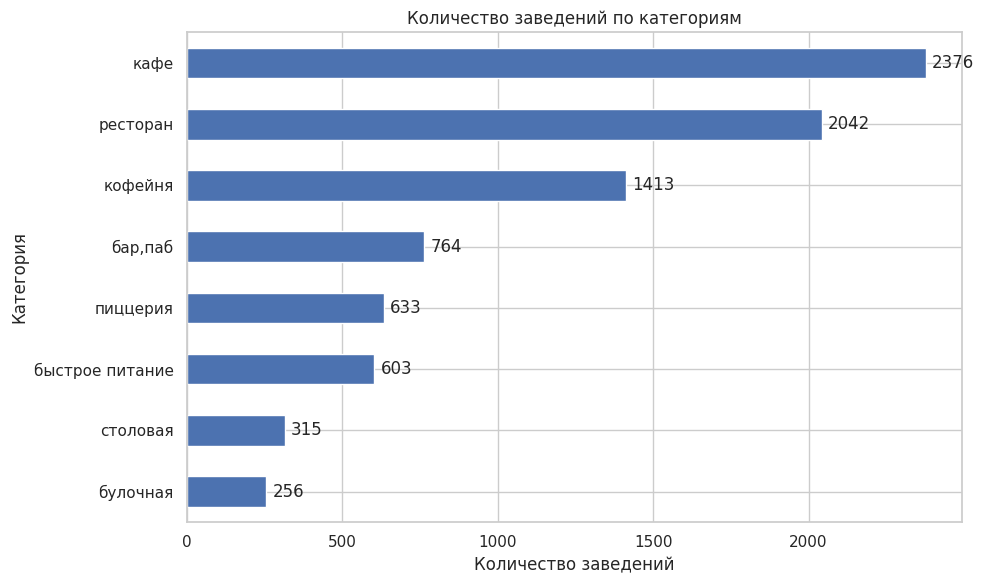

In [30]:
category_counts = df['category'].value_counts().sort_values()

plt.figure(figsize=(10, 6))
ax = category_counts.plot(kind='barh', color='#4C72B0')
for i, value in enumerate(category_counts):
    ax.text(value + 20, i, f'{value}', va='center')
plt.title('Количество заведений по категориям')
plt.xlabel('Количество заведений')
plt.ylabel('Категория')
plt.tight_layout()
plt.show()


Самые многочисленные категории кафе (2376), рестораны (2042) и кофейни (1413): вместе они формируют около 69% выборки. Реже всего встречаются столовые (315) и булочные (256)


### 3.2 Административные округа Москвы

Я исследовала распределение заведений по округам и отдельно проанализировала категории заведений в Центральном округе


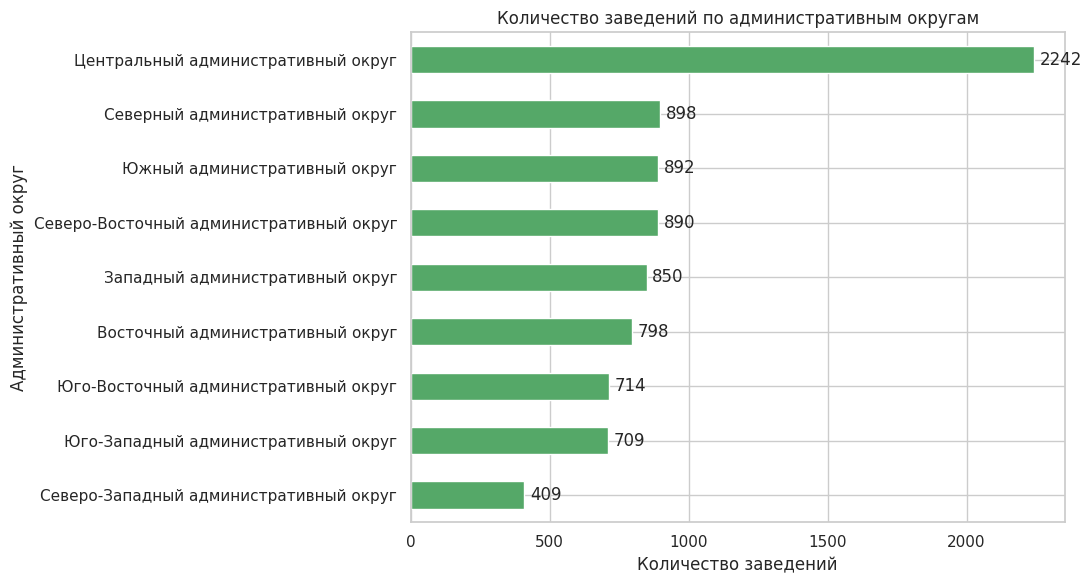

In [31]:
district_counts = df['district'].value_counts().sort_values()

plt.figure(figsize=(11, 6))
ax = district_counts.plot(kind='barh', color='#55A868')
for i, value in enumerate(district_counts):
    ax.text(value + 20, i, f'{value}', va='center')
plt.title('Количество заведений по административным округам')
plt.xlabel('Количество заведений')
plt.ylabel('Административный округ')
plt.tight_layout()
plt.show()


В данных представлены 9 административных округов Москвы. ЦАО заметно лидирует 2242 заведения, или около четверти выборки. Далее идут САО (898), ЮАО (892), СВАО (890) и ЗАО (850). Меньше всего заведений представлено в СЗАО 409.


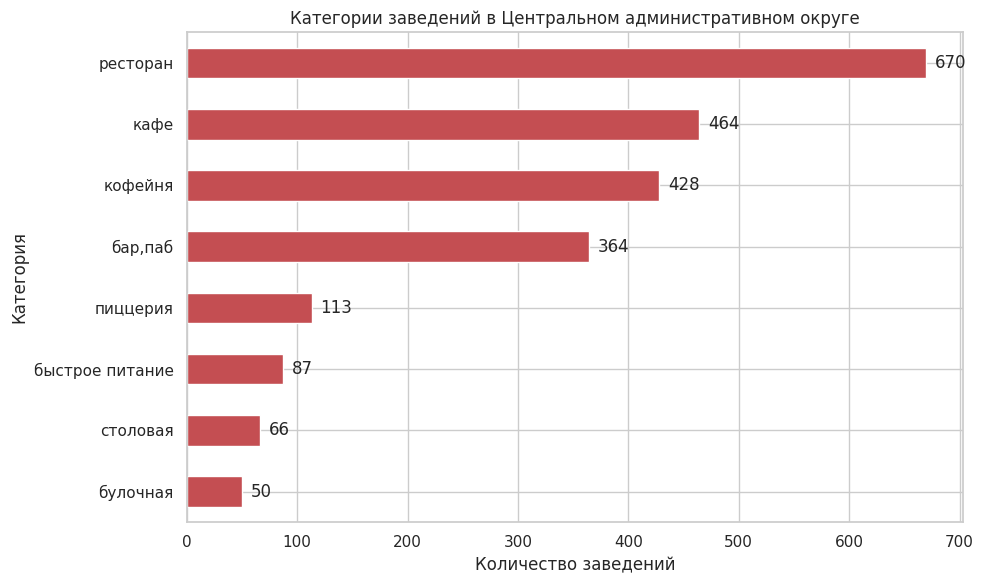

In [32]:
cao_categories = (
    df.loc[df['district'] == 'Центральный административный округ', 'category']
      .value_counts()
      .sort_values()
)

plt.figure(figsize=(10, 6))
ax = cao_categories.plot(kind='barh', color='#C44E52')
for i, value in enumerate(cao_categories):
    ax.text(value + 8, i, f'{value}', va='center')
plt.title('Категории заведений в Центральном административном округе')
plt.xlabel('Количество заведений')
plt.ylabel('Категория')
plt.tight_layout()
plt.show()


В ЦАО больше всего ресторанов (670), кафе (464) и кофеен (428). Бары и пабы также заметно представлены (364). Такая структура указывает на высокую концентрацию заведений досугового и ресторанного формата в центре.


### 3.3 Соотношение сетевых и несетевых заведений

**Задача:** изучить соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. Каких заведений больше — сетевых или несетевых? Какие категории заведений чаще являются сетевыми?


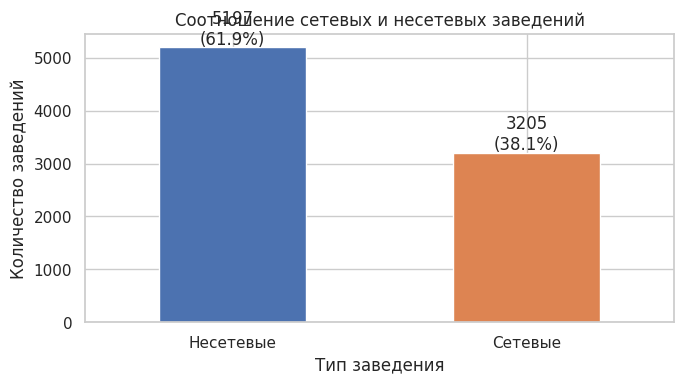

In [33]:
chain_overall = (
    df['chain'].map({0: 'Несетевые', 1: 'Сетевые'})
      .value_counts()
)

plt.figure(figsize=(7, 4))
ax = chain_overall.plot(kind='bar', color=['#4C72B0', '#DD8452'], rot=0)
for i, value in enumerate(chain_overall):
    ax.text(i, value + 60, f'{value}\n({value / len(df):.1%})', ha='center')
plt.title('Соотношение сетевых и несетевых заведений')
plt.xlabel('Тип заведения')
plt.ylabel('Количество заведений')
plt.tight_layout()
plt.show()


Несетевых заведений больше: 61,9% против 38,1% сетевых. Разница около 24 процентных пунктов


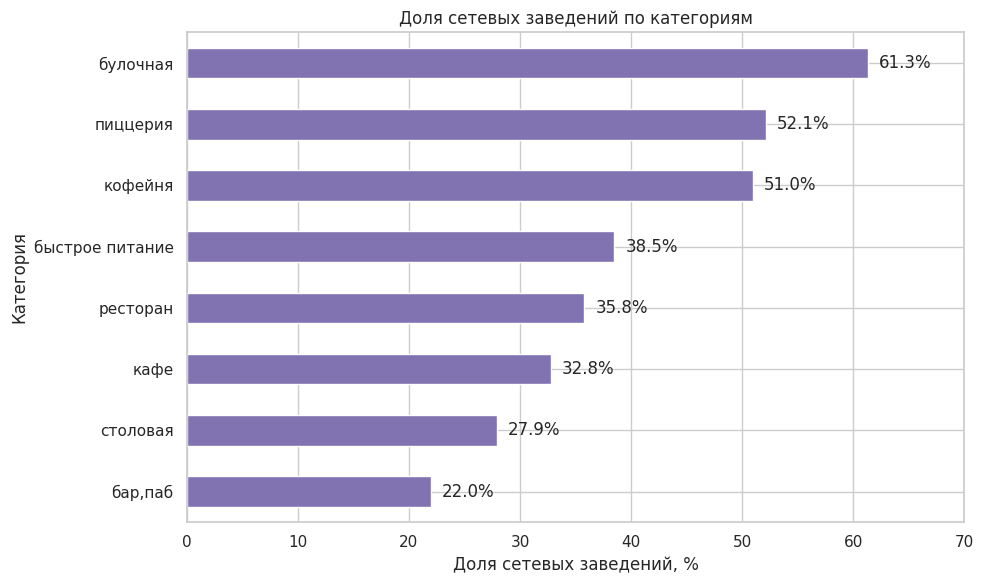

In [34]:
chain_share = (
    df.groupby('category')['chain'].mean()
      .mul(100)
      .sort_values()
)

plt.figure(figsize=(10, 6))
ax = chain_share.plot(kind='barh', color='#8172B2')
for i, value in enumerate(chain_share):
    ax.text(value + 1, i, f'{value:.1f}%', va='center')
plt.title('Доля сетевых заведений по категориям')
plt.xlabel('Доля сетевых заведений, %')
plt.ylabel('Категория')
plt.xlim(0, 70)
plt.tight_layout()
plt.show()


Чаще всего сетевыми являются булочные (61,3%), пиццерии (52,1%) и кофейни (51,0%). Реже всего сетевой формат встречается среди баров и пабов (22,0%). Предполагаю, потенциал масштабирования заметно зависит от категории.


### 3.4 Количество посадочных мест

**Задача:** исследовать количество посадочных мест в заведениях. Встречаются ли в данных аномальные значения или выбросы? Если да, то с чем они могут быть связаны? Привести для каждой категории заведений наиболее типичное количество посадочных мест.


In [35]:
seats_data = df.dropna(subset=['seats']).copy()
seats_data['seats'].describe()


count    4792.000000
mean      108.361436
std       122.841130
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64

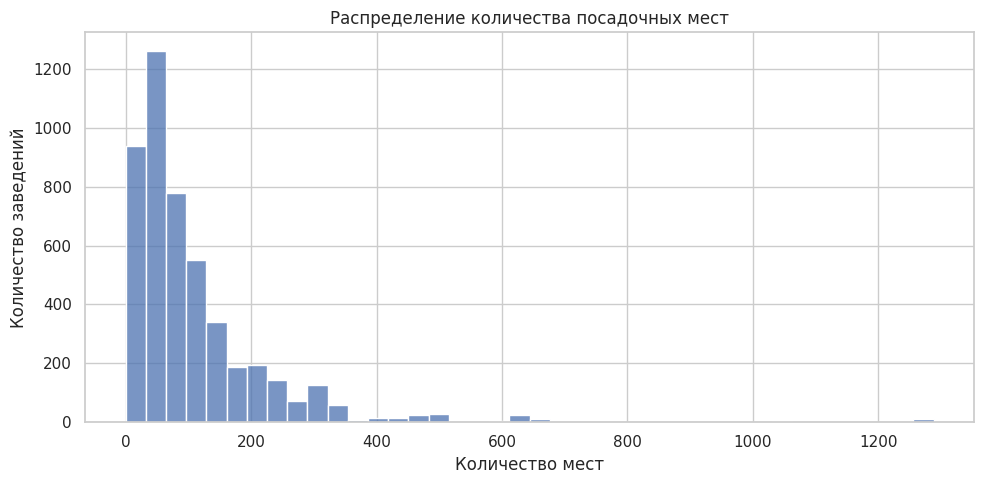

In [36]:
plt.figure(figsize=(10, 5))
sns.histplot(data=seats_data, x='seats', bins=40, color='#4C72B0')
plt.title('Распределение количества посадочных мест')
plt.xlabel('Количество мест')
plt.ylabel('Количество заведений')
plt.tight_layout()
plt.show()


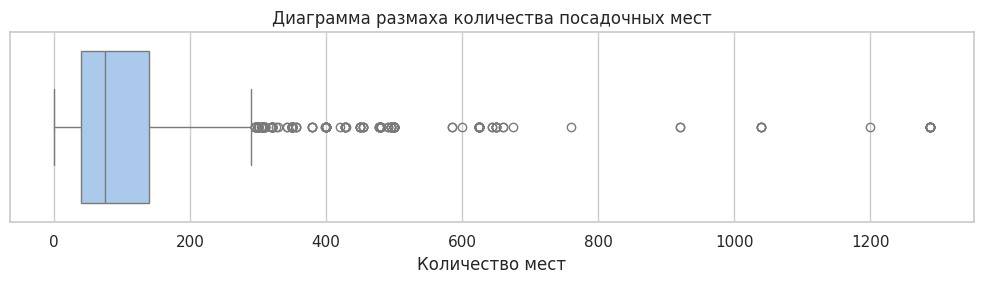

In [37]:
plt.figure(figsize=(10, 3))
sns.boxplot(data=seats_data, x='seats', color='#A1C9F4')
plt.title('Диаграмма размаха количества посадочных мест')
plt.xlabel('Количество мест')
plt.tight_layout()
plt.show()


Распределение имеет длинный правый хвост. Я определила выбросы по правилу 1,5 межквартильного размаха, но не удаляла их из исходного датафрейма.


In [38]:
q1 = seats_data['seats'].quantile(0.25)
q3 = seats_data['seats'].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
outlier_count = (seats_data['seats'] > upper_bound).sum()
zero_seats_count = (seats_data['seats'] == 0).sum()

print(f'Q1: {q1:.0f}, Q3: {q3:.0f}, IQR: {iqr:.0f}')
print(f'Верхняя граница выбросов: {upper_bound:.0f} мест')
print(f'Заведений выше границы: {outlier_count} ({outlier_count / len(seats_data):.1%})')
print(f'Заведений с 0 мест: {zero_seats_count} ({zero_seats_count / len(seats_data):.1%})')


Q1: 40, Q3: 140, IQR: 100
Верхняя граница выбросов: 290 мест
Заведений выше границы: 318 (6.6%)
Заведений с 0 мест: 136 (2.8%)


По правилу IQR значения выше 290 мест можно считать статистическими выбросами; таких заведений 318, или около 6,6% строк с известной вместимостью. Это не обязательно ошибки: крупные значения могут относиться к банкетным залам, столовым, фуд-кортам или объектам при гостиницах и транспортных узлах.

Отдельно обнаружены 136 заведений с нулём посадочных мест, около 2,8% строк с известным `seats`. Ноль может корректно обозначать формат навынос, но также может быть значением-индикатором отсутствующих данных. Поэтому я не удаляла эти строки.


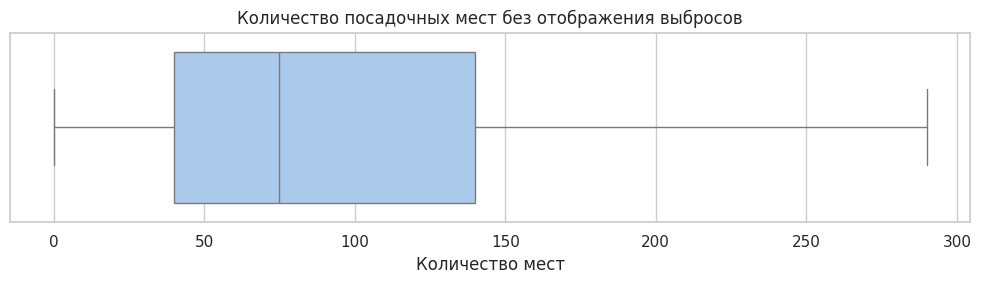

In [39]:
plt.figure(figsize=(10, 3))
sns.boxplot(data=seats_data, x='seats', showfliers=False, color='#A1C9F4')
plt.title('Количество посадочных мест без отображения выбросов')
plt.xlabel('Количество мест')
plt.tight_layout()
plt.show()


Медиана составляет 75 мест, а центральные 50% значений находятся между 40 и 140 местами. Из-за сильной асимметрии типичную вместимость корректнее описывать медианой, а не средним.


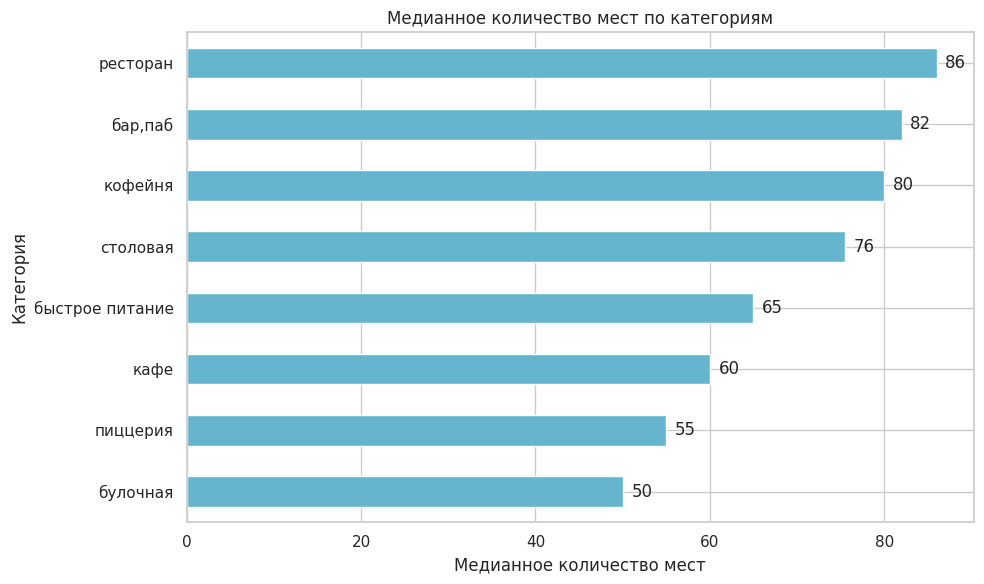

In [40]:
median_seats = (
    seats_data.groupby('category')['seats'].median()
              .sort_values()
)

plt.figure(figsize=(10, 6))
ax = median_seats.plot(kind='barh', color='#64B5CD')
for i, value in enumerate(median_seats):
    ax.text(value + 1, i, f'{value:.0f}', va='center')
plt.title('Медианное количество мест по категориям')
plt.xlabel('Медианное количество мест')
plt.ylabel('Категория')
plt.tight_layout()
plt.show()


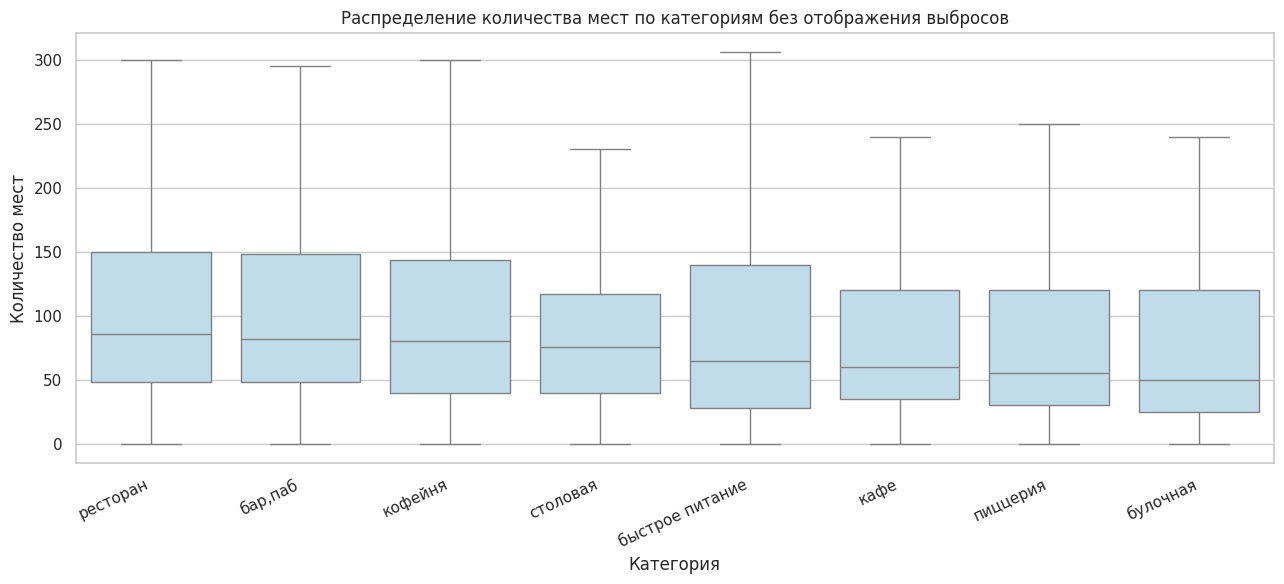

In [41]:
order = median_seats.sort_values(ascending=False).index

plt.figure(figsize=(13, 6))
sns.boxplot(data=seats_data, x='category', y='seats', order=order,
            showfliers=False, color='#B9DDF1')
plt.title('Распределение количества мест по категориям без отображения выбросов')
plt.xlabel('Категория')
plt.ylabel('Количество мест')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()


Наибольшая типичная вместимость у ресторанов (медиана 86 мест), баров/пабов (82) и кофеен (80). Наименьшая у булочных (50) и пиццерий (55). Выбросы могут быть как реальными крупными объектами, так и ошибками ручного ввода, поэтому без дополнительной проверки адресов удалять их не буду.


### 3.5 Рейтинг заведений  

**Задача:** исследовать рейтинг заведений. Визуализировать распределение средних рейтингов по категориям заведений. Сильно ли различаются усреднённые рейтинги для разных типов общепита?

In [42]:
rating_stats = df.groupby('category')['rating'].agg(['count', 'mean', 'median', 'std'])
rating_stats.sort_values('mean', ascending=False).round(3)


,count,mean,median,std
category,,,,
"бар,паб",764,4.388,4.4,0.380
пиццерия,633,4.301,4.3,0.336
ресторан,2042,4.290,4.3,0.413
кофейня,1413,4.277,4.3,0.372
булочная,256,4.268,4.3,0.386
столовая,315,4.211,4.3,0.454
кафе,2376,4.124,4.2,0.566
быстрое питание,603,4.050,4.2,0.561


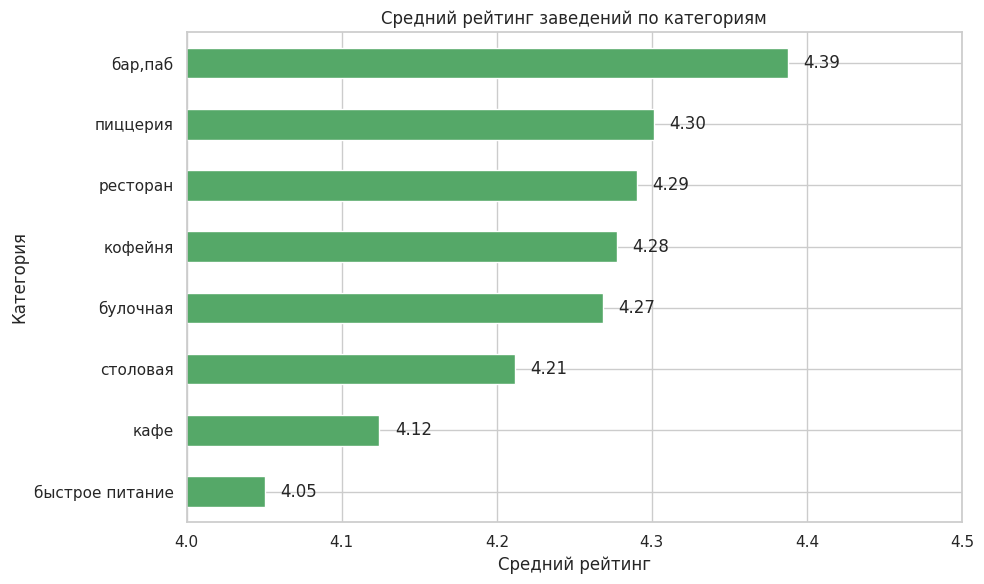

In [43]:
rating_by_category = df.groupby('category')['rating'].mean().sort_values()

plt.figure(figsize=(10, 6))
ax = rating_by_category.plot(kind='barh', color='#55A868')
for i, value in enumerate(rating_by_category):
    ax.text(value + 0.01, i, f'{value:.2f}', va='center')
plt.title('Средний рейтинг заведений по категориям')
plt.xlabel('Средний рейтинг')
plt.ylabel('Категория')
plt.xlim(4.0, 4.5)
plt.tight_layout()
plt.show()


Оценим разброс средних рейтингов между категориями.


In [44]:
rating_by_category.describe()


count    8.000000
mean     4.238871
std      0.107241
min      4.050249
25%      4.189643
50%      4.272821
75%      4.293117
max      4.387696
Name: rating, dtype: float64

Средние рейтинги различаются слабо: от 4,05 у быстрого питания до 4,39 у баров и пабов, то есть разница между крайними категориями составляет около 0,34 балла. Стандартное отклонение восьми средних около 0,11. Категория связана с рейтингом, но различия невелики по шкале от 1 до 5.


### 3.6 Связь рейтинга с другими признаками

Для смешанных числовых и категориальных признаков я использовала коэффициент Phi-k. `seats` и `rating` явно указала как интервальные переменные, чтобы количество мест не было ошибочно воспринято как категория.


In [45]:
correlation_columns = [
    'district', 'category', 'chain', 'seats', 'price', 'is_24_7', 'rating'
]
correlation_data = df[correlation_columns].copy()

# Для Phi-k представим логический признак как категориальный текст.
correlation_data['is_24_7'] = (
    correlation_data['is_24_7']
      .map({True: 'да', False: 'нет'})
      .astype(object)
)


In [46]:
correlation_matrix = correlation_data.phik_matrix(
    interval_cols=['seats', 'rating']
)
rating_correlations = (
    correlation_matrix['rating']
      .drop('rating')
      .sort_values(ascending=False)
)
rating_correlations


price       0.220295
district    0.200761
category    0.189716
is_24_7     0.150365
chain       0.108114
seats       0.000000
Name: rating, dtype: float64

In [47]:
rating_correlations.to_frame('Phi-k с рейтингом').round(3)


,Phi-k с рейтингом
price,0.220
district,0.201
category,0.190
is_24_7,0.150
chain,0.108
seats,0.000


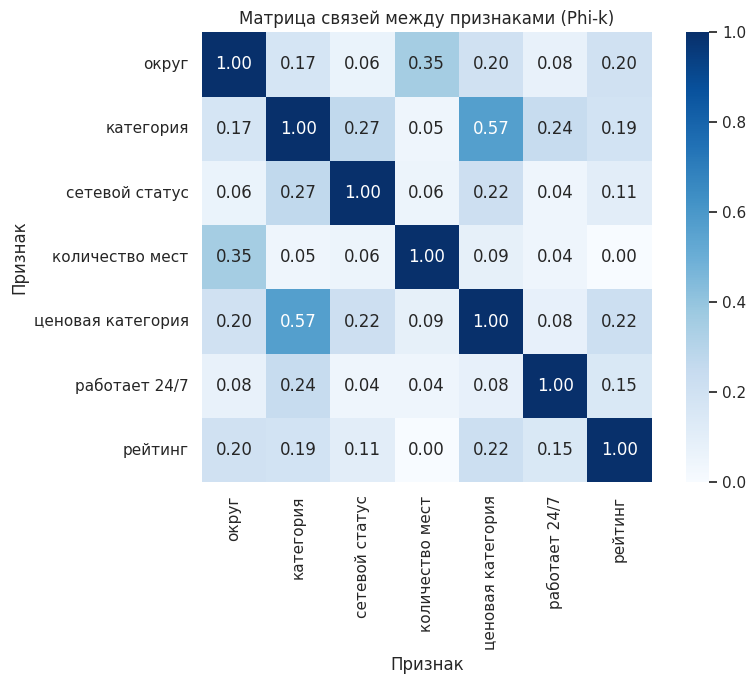

In [48]:
correlation_labels = {
    'district': 'округ',
    'category': 'категория',
    'chain': 'сетевой статус',
    'seats': 'количество мест',
    'price': 'ценовая категория',
    'is_24_7': 'работает 24/7',
    'rating': 'рейтинг'
}
correlation_matrix_for_plot = correlation_matrix.rename(
    index=correlation_labels, columns=correlation_labels
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix_for_plot,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    vmin=0,
    vmax=1,
    square=True
)
plt.title('Матрица связей между признаками (Phi-k)')
plt.xlabel('Признак')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()


Самая сильная из найденных связей это свзяль между рейтингом и ценовой категорией (`Phi-k ≈ 0,22`), но и она слабая. Далее идут округ (`≈ 0,20`) и категория заведения (`≈ 0,19`). Для количества мест при корректном указании интервального типа связь практически отсутствует. При этом `seats` заполнен только для 4792 из 8402 заведений, примерно 57% выборки, поэтому вывод об отсутствии связи относится только к строкам с известной вместимостью и требует осторожной интерпретации.

Связь с `is_24_7` также следует интерпретировать осторожно: для 535 заведений режим работы неизвестен, но по формальному условию проекта в логическом признаке им присвоено `False`.


In [49]:
rating_price_stats = (
    df.groupby('price')['rating']
      .agg(count='count', mean='mean', median='median')
      .sort_values('mean', ascending=False)
)
rating_price_stats.round(3)


,count,mean,median
price,,,
высокие,478,4.437,4.4
выше среднего,564,4.386,4.4
средние,2117,4.298,4.3
низкие,156,4.173,4.2


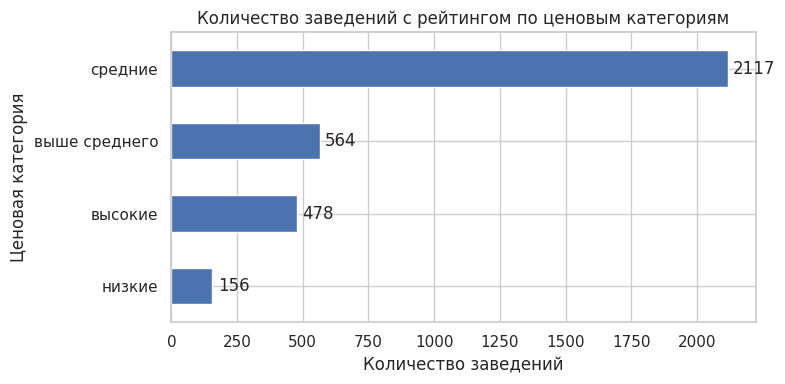

In [50]:
price_counts = rating_price_stats['count'].sort_values()

plt.figure(figsize=(8, 4))
ax = price_counts.plot(kind='barh', color='#4C72B0')
for i, value in enumerate(price_counts):
    ax.text(value + 20, i, f'{value}', va='center')
plt.title('Количество заведений с рейтингом по ценовым категориям')
plt.xlabel('Количество заведений')
plt.ylabel('Ценовая категория')
plt.tight_layout()
plt.show()


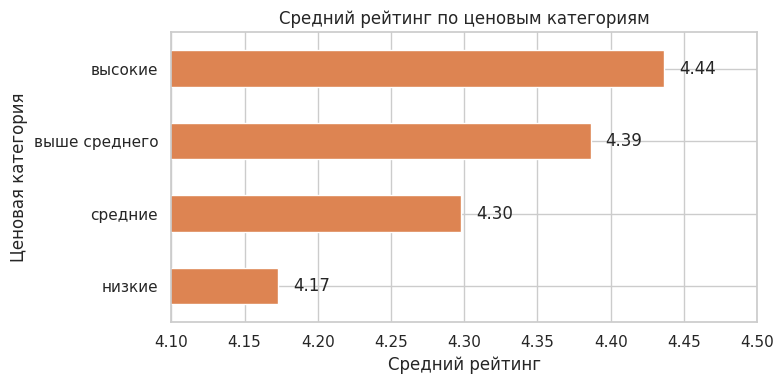

In [51]:
price_rating = rating_price_stats['mean'].sort_values()

plt.figure(figsize=(8, 4))
ax = price_rating.plot(kind='barh', color='#DD8452')
for i, value in enumerate(price_rating):
    ax.text(value + 0.01, i, f'{value:.2f}', va='center')
plt.title('Средний рейтинг по ценовым категориям')
plt.xlabel('Средний рейтинг')
plt.ylabel('Ценовая категория')
plt.xlim(4.1, 4.5)
plt.tight_layout()
plt.show()


Средний рейтинг последовательно повышается от низкой ценовой категории (4,17) к высокой (4,44). Однако группы сильно различаются по размеру: в категории «средние» 2117 заведений, а в категории «низкие» только 156. Поэтому результат показывает слабую ассоциацию, но не доказывает, что более высокая цена сама по себе повышает рейтинг.


### 3.7 Топ-15 популярных сетей в Москве

Сначала я сгруппировала все заведения по `name_norm` без предварительного фильтра по `chain`. В верхней части списка появились общие названия «Кафе», «Шаурма» и «Ресторан», у которых нет ни одной отметки `chain = 1`; такие группы нельзя уверенно считать брендами. Поэтому к сетям я отнесла названия, у которых хотя бы одна точка помечена как сетевая, но при подсчёте размера сети учла все точки с этим названием. Такой подход сохраняет отдельные ошибочно размеченные нулём филиалы уже подтверждённых сетей.


In [52]:
def first_mode(series):
    mode = series.mode()
    return mode.iloc[0] if not mode.empty else series.iloc[0]

name_stats = (
    df.groupby('name_norm')
      .agg(
          name=('name', first_mode),
          count=('id', 'size'),
          chain_marks=('chain', 'sum'),
          chain_share=('chain', 'mean'),
          avg_rating=('rating', 'mean'),
          category=('category', first_mode)
      )
)

print('Крупнейшие группы без предварительного фильтра по chain:')
display(
    name_stats.sort_values('count', ascending=False)
              .head(15)[['name', 'count', 'chain_marks', 'chain_share']]
)

top_15 = (
    name_stats[name_stats['chain_marks'] > 0]
      .sort_values('count', ascending=False)
      .head(15)
      .reset_index(drop=True)
)
top_15


Крупнейшие группы без предварительного фильтра по chain:


,name,count,chain_marks,chain_share
name_norm,,,,
кафе,Кафе,188,0,0.000000
шоколадница,Шоколадница,120,120,1.000000
домино'с пицца,Домино'с Пицца,77,76,0.987013
додо пицца,Додо Пицца,74,74,1.000000
one price coffee,One Price Coffee,72,71,0.986111
яндекс лавка,Яндекс Лавка,69,69,1.000000
cofix,Cofix,65,65,1.000000
prime,Prime,50,50,1.000000
хинкальная,Хинкальная,44,44,1.000000


,name,count,chain_marks,chain_share,avg_rating,category
0,Шоколадница,120,120,1.000000,4.177500,кофейня
1,Домино'с Пицца,77,76,0.987013,4.171429,пиццерия
2,Додо Пицца,74,74,1.000000,4.286486,пиццерия
3,One Price Coffee,72,71,0.986111,4.069444,кофейня
4,Яндекс Лавка,69,69,1.000000,3.872464,ресторан
5,Cofix,65,65,1.000000,4.075385,кофейня
6,Prime,50,50,1.000000,4.116000,ресторан
7,Хинкальная,44,44,1.000000,4.322727,кафе
8,КОФЕПОРТ,42,42,1.000000,4.147619,кофейня
9,Кулинарная лавка братьев Караваевых,39,39,1.000000,4.394872,кафе


In [53]:
top_15['category'].value_counts()


category
кофейня     5
кафе        4
ресторан    3
пиццерия    2
булочная    1
Name: count, dtype: int64

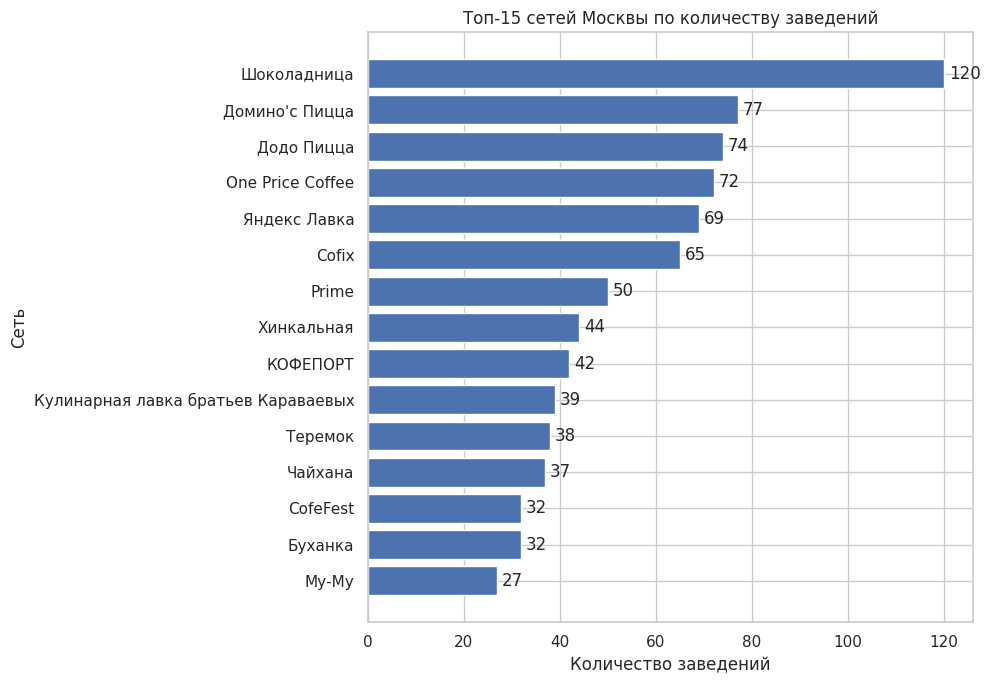

In [54]:
top_for_plot = top_15.sort_values('count')

plt.figure(figsize=(10, 7))
ax = plt.barh(top_for_plot['name'], top_for_plot['count'], color='#4C72B0')
for bar in ax:
    plt.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
             f'{int(bar.get_width())}', va='center')
plt.title('Топ-15 сетей Москвы по количеству заведений')
plt.xlabel('Количество заведений')
plt.ylabel('Сеть')
plt.tight_layout()
plt.show()


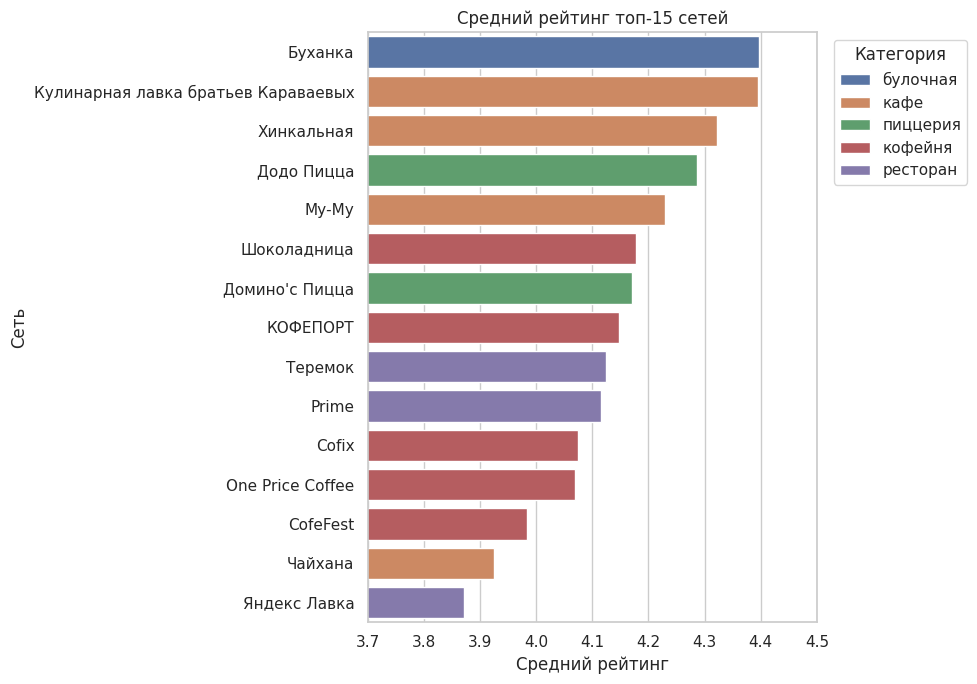

In [55]:
plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_15.sort_values('avg_rating', ascending=False),
    y='name',
    x='avg_rating',
    hue='category',
    dodge=False
)
plt.title('Средний рейтинг топ-15 сетей')
plt.xlabel('Средний рейтинг')
plt.ylabel('Сеть')
plt.xlim(3.7, 4.5)
plt.legend(title='Категория', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


Проверка без фильтра по `chain` показала, что крупные группы «Кафе», «Шаурма» и «Ресторан» целиком помечены как несетевые и являются скорее общими названиями формата, чем брендами. Среди подтверждённых сетей по количеству заведений лидируют «Шоколадница» (120), «Домино'с Пицца» (77), «Додо Пицца» (74) и One Price Coffee (72). Для «Домино'с Пиццы» и One Price Coffee учтено по одной точке с ошибочной отметкой `chain = 0`.

В топ-15 входят 5 кофеен, 4 кафе, 3 ресторана, 2 пиццерии и 1 булочная. Самый высокий средний рейтинг среди них у «Буханки», около 4,40, а самый низкий у «Яндекс Лавки», около 3,87

### 3.8 Средний чек по округам

Я изучила вариацию `middle_avg_bill` по административным округам. Поскольку в данных нет координат, точное расстояние до центра рассчитать нельзя, поэтому я сравнила ЦАО с другими округами и использовала округ как приближённый географический признак.


In [56]:
df['middle_avg_bill'].describe()

count     3149.000000
mean       958.053668
std       1009.732845
min          0.000000
25%        375.000000
50%        750.000000
75%       1250.000000
max      35000.000000
Name: middle_avg_bill, dtype: float64

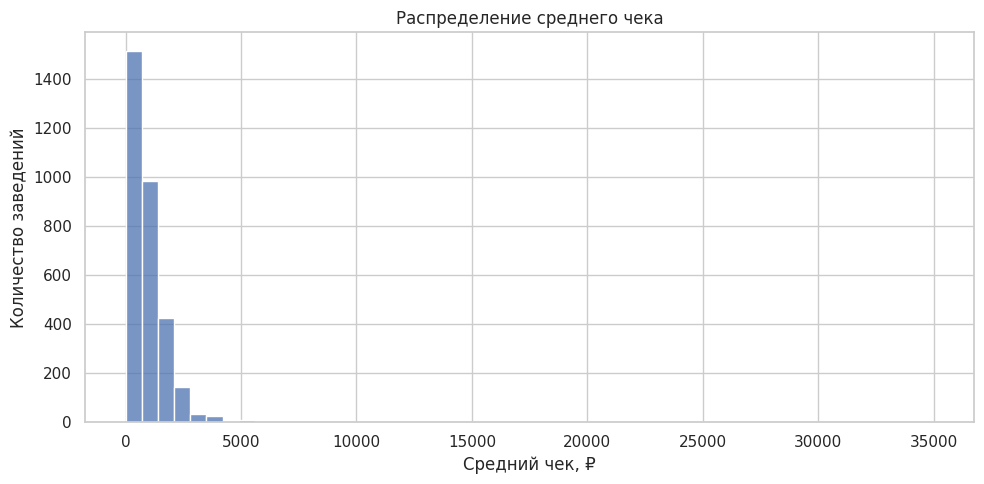

In [57]:
plt.figure(figsize=(10, 5))
sns.histplot(df['middle_avg_bill'].dropna(), bins=50, color='#4C72B0')
plt.title('Распределение среднего чека')
plt.xlabel('Средний чек, ₽')
plt.ylabel('Количество заведений')
plt.tight_layout()
plt.show()


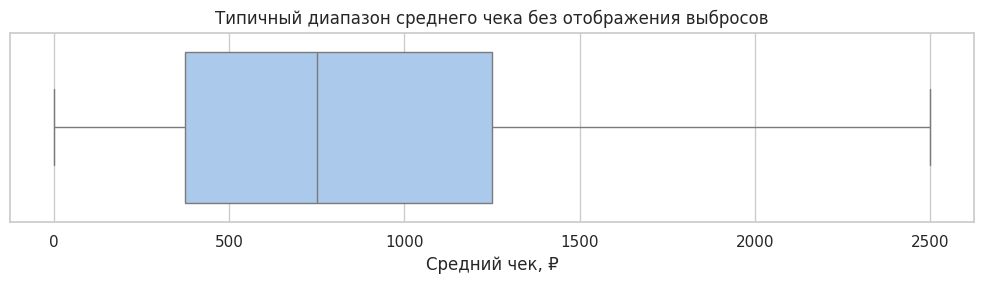

In [58]:
plt.figure(figsize=(10, 3))
sns.boxplot(data=df, x='middle_avg_bill', showfliers=False, color='#A1C9F4')
plt.title('Типичный диапазон среднего чека без отображения выбросов')
plt.xlabel('Средний чек, ₽')
plt.tight_layout()
plt.show()


Распределение среднего чека имеет сильную правостороннюю асимметрию: медиана равна 750 ₽, а среднее — около 958 ₽ из-за редких высоких значений вплоть до 35 000 ₽. Поэтому при сравнении округов основной показатель медиана.


In [59]:
bill_by_district = (
    df.groupby('district')['middle_avg_bill']
      .agg(count='count', median='median', mean='mean')
      .sort_values('median', ascending=False)
)
bill_by_district.round(1)


,count,median,mean
district,,,
Западный административный округ,306,1000.0,1053.2
Центральный административный округ,1060,1000.0,1191.1
Северо-Западный административный округ,157,700.0,822.2
Северный административный округ,322,650.0,928.0
Юго-Западный административный округ,235,600.0,792.6
Восточный административный округ,260,575.0,820.6
Северо-Восточный административный округ,301,500.0,716.6
Южный административный округ,314,500.0,834.4
Юго-Восточный административный округ,194,450.0,654.1


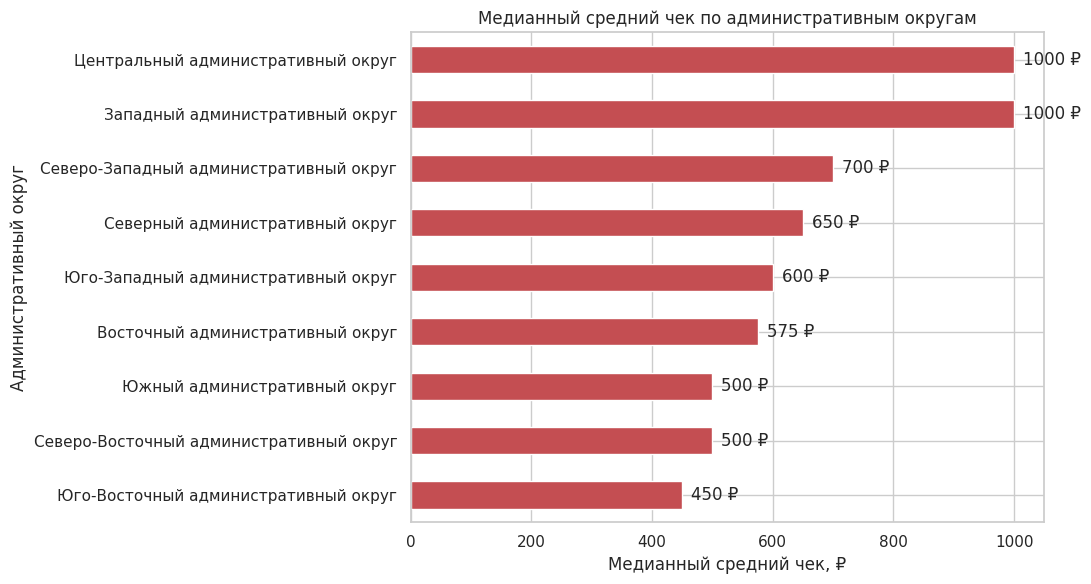

In [60]:
district_medians = bill_by_district['median'].sort_values()

plt.figure(figsize=(11, 6))
ax = district_medians.plot(kind='barh', color='#C44E52')
for i, value in enumerate(district_medians):
    ax.text(value + 15, i, f'{value:.0f} ₽', va='center')
plt.title('Медианный средний чек по административным округам')
plt.xlabel('Медианный средний чек, ₽')
plt.ylabel('Административный округ')
plt.tight_layout()
plt.show()


,count,median,mean
area_group,,,
Другие округа,2089,600.0,839.8
ЦАО,1060,1000.0,1191.1


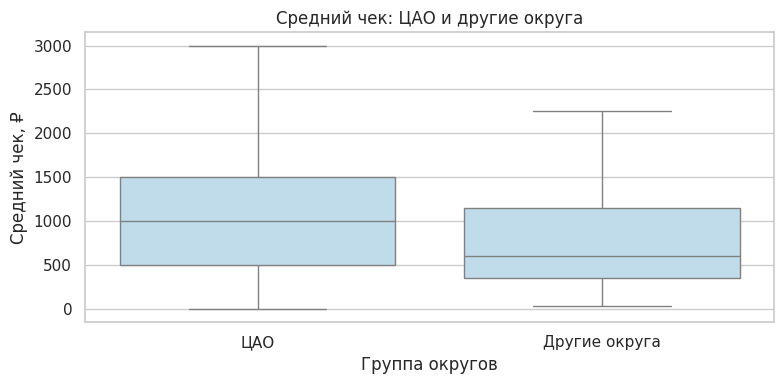

In [61]:
df['area_group'] = np.where(
    df['district'] == 'Центральный административный округ',
    'ЦАО',
    'Другие округа'
)

center_comparison = (
    df.groupby('area_group')['middle_avg_bill']
      .agg(count='count', median='median', mean='mean')
)
display(center_comparison.round(1))

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='area_group', y='middle_avg_bill', showfliers=False,
            order=['ЦАО', 'Другие округа'], color='#B9DDF1')
plt.title('Средний чек: ЦАО и другие округа')
plt.xlabel('Группа округов')
plt.ylabel('Средний чек, ₽')
plt.tight_layout()
plt.show()


Медианный чек в ЦАО составляет 1000 руб против 600 руб в остальных округах. Такой же медианный уровень наблюдается в ЗАО, а минимальный в ЮВАО (450 ₽). В среднем чек в центре выше, но утверждать о точной зависимости от расстояния нельзя: административный округ грубый географический признак.

### Промежуточный вывод

- Наиболее распространены кафе, рестораны и кофейни; больше всего заведений находится в ЦАО.
- Несетевые объекты преобладают (61,9%). Сетевой формат особенно характерен для булочных, пиццерий и кофеен.
- Медиана вместимости 75 мест; типичные значения зависят от категории. Крупные значения требуют отдельной проверки, но не были автоматически удалены.
- Средние рейтинги категорий близки: от 4,05 до 4,39. Самая сильная связь рейтинга обнаружена с ценовой категорией, но она слабая (`Phi-k ≈ 0,22`).
- Крупнейшие сети по числу точек это «Шоколадница», «Домино'с Пицца», «Додо Пицца» и One Price Coffee.
- Медианный чек в ЦАО равен 1000 руб, в остальных округах в совокупности 600 руб

## Итоговый вывод и рекомендации

### 1. Общий обзор

Я объединила данные о 8406 заведениях и ценах для части из них, проверила типы, пропуски и дубликаты и создала признак круглосуточной работы. После нормализации названий и адресов я удалила 4 повторные строки, около 0,05% выборки. Пропуски в числе мест и ценах не стала заполнять искусственно. Затем я проанализировала категории, округа, сетевой статус, вместимость, рейтинги, крупнейшие сети и средний чек.

### 2. Главные результаты

- Рынок сосредоточен вокруг кафе, ресторанов и кофеен; ЦАО содержит 2242 заведения и является наиболее насыщенным округом.
- Несетевые заведения составляют 61,9%. При этом более половины булочных, пиццерий и кофеен относятся к сетям.
- Типичная вместимость 75 мест. Медианы выше у ресторанов (86), баров/пабов (82) и кофеен (80), ниже у булочных (50) и пиццерий (55).
- Средние рейтинги категорий близки. Наивысший показатель у баров/пабов — около 4,39, минимальный у быстрого питания — около 4,05.
- Связи рейтинга со структурными признаками слабые. Максимальный Phi-k у ценовой категории около 0,22; более дорогие группы имеют несколько более высокий средний рейтинг, но это не доказывает причинную связь.
- Самые распространённые сети это «Шоколадница», «Домино'с Пицца», «Додо Пицца» и One Price Coffee.
- Медианный чек в ЦАО 1000 руб, а в остальных округах в совокупности 600 руб. Центр допускает более высокий чек, но одновременно характеризуется высокой концентрацией конкурентов.

### 3. Рекомендации заказчику

1. **Для масштабируемой сетевой модели** я бы смотрела в сторону пиццерии, кофейни или булочной: в этих категориях доля сетевых заведений превышает 50%, то есть формат хорошо поддаётся стандартизации. При этом кофейни уже многочисленны, поэтому нужно будет заметное позиционирование.
2. **Для самостоятельного авторского проекта** рассмотреть бар/паб: категория сравнительно небольшая, преимущественно несетевая и имеет самый высокий средний рейтинг. Однако перед решением необходимо проверить локальную конкуренцию и вечерний трафик.
3. **Локацию и чек выбирать совместно.** В ЦАО можно ориентироваться на более высокий чек около 1000 руб, но конкуренция там максимальна. Для массового формата за пределами центра разумнее тестировать чек ближе к 600 руб и отдельно оценивать трафик конкретной точки.
4. **Площадь подбирать по формату:** ориентир медианы около 80–90 мест для ресторана или бара и 50/80 мест для более компактных форматов
5. До инвестирования было бы здорово дополнить анализ арендными ставками, пешеходным трафиком, плотностью конкурентов, демографией и выручкой. Текущий датасет описывает предложение рынка, но не спрос. А мы живем в мире спроса и предложения :)
